# Байесовская неопределённость при выборочном ответе языковых моделей

**MVP исследовательского пайплайна.** Ноутбук проверяет вопрос: *улучшает ли байесовская оценка неопределённости компромисс между покрытием ответов и частотой ошибок?*

В эксперименте локально запускается инструктивная LLM, которая отвечает на вопросы научного теста в формате выбора одного из четырёх вариантов. Для каждого вопроса вычисляются несколько оценок уверенности. Затем строятся кривые риск–покрытие и сравниваются AURC, доля ошибок при заданном покрытии и калибровка вероятности правильного ответа.

### Гипотезы

- **H1 (основная):** байесовская оценка `P(ответ верен | признаки LLM)` даёт меньшую площадь под кривой риск–покрытие (AURC) и/или меньший риск при фиксированном покрытии, чем оценки без калибровки.
- **H0:** выигрыша нет; наблюдаемые различия объясняются шумом тестовой выборки.
- **Вторичный вопрос:** связан ли возможный выигрыш именно с байесовским усреднением по параметрам калибратора или достаточно точечной MAP-калибровки?

### Дизайн MVP

1. **Данные.** SciQ (`allenai/sciq`), вопросы с одним правильным и тремя отвлекающими вариантами. Варианты перемешиваются. Калибровка — на `validation`, финальная оценка — на `test`; выборки не пересекаются.
2. **Локальная LLM.** `Qwen/Qwen2.5-7B-Instruct` в 4-битной квантизации NF4 (bitsandbytes; ~6–7 ГБ VRAM), один прямой проход на вопрос. По логитам получаем распределение вероятностей по буквам A–D.
3. **Выборочный ответ.** Для каждого вопроса делаем `K=16` независимых Monte-Carlo вытягиваний из предсказательного распределения модели. Это эквивалентно одношаговой генерации с температурой 1, но существенно дешевле полной генерации текста.
4. **Оценки неопределённости.**
   - `MSP` — максимальная вероятность варианта;
   - `Choice-entropy` — нормированная энтропия распределения по вариантам;
   - `Sample-agreement` — доля самого частого ответа среди `K` выборок;
   - `Sample-entropy` — нормированная энтропия эмпирического распределения выборок;
   - `Bayes-answer` — апостериорная вероятность модального ответа в модели Дирихле (контрольная проверка);
   - `MAP-risk` — точечная логистическая калибровка `P(верно | признаки)`;
   - `Bayes-risk` — байесовская логистическая калибровка с лапласовским приближением и усреднением по апостериорным параметрам.
5. **Метрики.** Кривые риск–покрытие, AURC, AUROC, риск при покрытии 50/70/80/90 %, Brier score, ECE и парные bootstrap-интервалы для разностей.

### Что важно знать заранее

- `Bayes-risk` использует размеченную калибровочную выборку. Это не «бесплатная» неопределённость самой LLM, а байесовская модель правильности ответа. Поэтому в сравнение включён `MAP-risk` с теми же признаками: он отделяет эффект байесовского усреднения от эффекта обычной калибровки.
- `Bayes-answer` при фиксированном `K` и симметричном приоре Дирихле монотонно эквивалентен `Sample-agreement`, поэтому его AURC должен с ним совпасть. Это намеренная санитарная проверка: байесовский ярлык сам по себе не обязан улучшать отбор.
- Основной результат — не обещание превосходства метода, а воспроизводимая процедура проверки. Отрицательный результат также содержателен.
- Тестовая выборка мала, поэтому выводы носят исследовательский, а не окончательный характер. Для публикации нужны несколько моделей, датасетов, seed и предрегистрация основной метрики.

## 0. Установка и импорты

In [1]:
%pip install -q -U "bitsandbytes>=0.46.1"

In [2]:
import json
import math
import platform
import random
import re
import time
import warnings
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from IPython.display import Markdown, display
from scipy.special import expit
from sklearn.metrics import roc_auc_score
from transformers import AutoModelForCausalLM, AutoTokenizer
from transformers import __version__ as transformers_version

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 180)
np.set_printoptions(precision=4, suppress=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

print(f"Python: {platform.python_version()}")
print(f"PyTorch: {torch.__version__}; CUDA доступна: {torch.cuda.is_available()}")
print(f"Transformers: {transformers_version}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
else:
    print("GPU не найден: вычисления пойдут на CPU и будут заметно медленнее.")

Python: 3.13.16
PyTorch: 2.11.0+cu130; CUDA доступна: True
Transformers: 5.20.2
GPU: Tesla T4


## 1. Конфигурация

In [3]:
MODEL_ID = "Qwen/Qwen2.5-7B-Instruct"
DATASET_ID = "allenai/sciq"
RUN_NAME = "sciq_qwen25_7b_4bit_bayes_selective_mvp"

N_CALIBRATION = 250
N_TEST = 350
N_SAMPLES = 16
BATCH_SIZE = 2
SEED = 42

LOAD_IN_4BIT = True
DIRICHLET_ALPHA = 1.0
PRIOR_SCALE = 2.0
N_POSTERIOR_DRAWS = 2000
N_BOOTSTRAP = 1000
N_ECE_BINS = 10
TARGET_COVERAGES = (0.50, 0.70, 0.80, 0.90)

RUN_DIR = Path("runs") / RUN_NAME
set_seed(SEED)

print(json.dumps({
    "run_name": RUN_NAME,
    "model": MODEL_ID,
    "dataset": DATASET_ID,
    "batch_size": BATCH_SIZE,
    "n_calibration": N_CALIBRATION,
    "n_test": N_TEST,
    "n_samples": N_SAMPLES,
    "device": DEVICE,
    "load_in_4bit": LOAD_IN_4BIT,
}, ensure_ascii=False, indent=2))

{
  "run_name": "sciq_qwen25_7b_4bit_bayes_selective_mvp",
  "model": "Qwen/Qwen2.5-7B-Instruct",
  "dataset": "allenai/sciq",
  "batch_size": 2,
  "n_calibration": 250,
  "n_test": 350,
  "n_samples": 16,
  "device": "cuda",
  "load_in_4bit": true
}


## 2. Данные: контролируемый множественный выбор

SciQ содержит короткие научные вопросы и ровно четыре варианта (правильный + три дистрактора). Мы перемешиваем варианты отдельно для каждого вопроса и сохраняем позицию правильного ответа. Такая постановка делает проверку ответа детерминированной и исключает влияние парсера свободного текста на оценку неопределённости.

Калибровочная и тестовая части берутся из разных официальных split'ов. Вопросы, у которых варианты совпадают после нормализации, пропускаются.

In [4]:
LETTERS = ("A", "B", "C", "D")

def build_sciq_mcq(n_calibration: int, n_test: int, seed: int) -> pd.DataFrame:
    dataset = load_dataset(DATASET_ID)
    rng = np.random.default_rng(seed)
    rows = []

    for split_name, n_target in (("validation", n_calibration), ("test", n_test)):
        split_data = dataset[split_name].shuffle(seed=seed + int(split_name == "test"))
        added = 0
        for example in split_data:
            raw_options = [
                example["correct_answer"],
                example["distractor1"],
                example["distractor2"],
                example["distractor3"],
            ]
            options = [re.sub(r"\s+", " ", str(x)).strip() for x in raw_options]
            if any(not x for x in options):
                continue
            if len({x.casefold() for x in options}) < 4:
                continue

            permutation = rng.permutation(4)
            shuffled_options = [options[i] for i in permutation]
            correct_idx = int(np.flatnonzero(permutation == 0)[0])

            rows.append({
                "qid": f"{split_name}-{added:04d}",
                "source_split": split_name,
                "question": re.sub(r"\s+", " ", str(example["question"])).strip(),
                "options": shuffled_options,
                "correct_idx": correct_idx,
                "correct_letter": LETTERS[correct_idx],
                "correct_answer": options[0],
            })
            added += 1
            if added >= n_target:
                break
        if added < n_target:
            raise RuntimeError(f"В split {split_name} нашлось только {added} валидных примеров.")

    frame = pd.DataFrame(rows)
    overlap = set(frame.loc[frame.source_split == "validation", "question"]) & set(
        frame.loc[frame.source_split == "test", "question"]
    )
    if overlap:
        raise RuntimeError(f"Найдено пересечение вопросов между split'ами: {len(overlap)}")

    for idx, row in frame.iterrows():
        assert row["options"][row["correct_idx"]] == row["correct_answer"]
    return frame


data = build_sciq_mcq(N_CALIBRATION, N_TEST, SEED)
cal_df = data[data["source_split"] == "validation"].reset_index(drop=True).copy()
test_df = data[data["source_split"] == "test"].reset_index(drop=True).copy()

print(f"Калибровка: {len(cal_df)} вопросов; тест: {len(test_df)} вопросов")
display(
    data.assign(options_preview=data["options"].apply(lambda x: " | ".join(x)))
        [["qid", "question", "options_preview", "correct_letter"]]
        .head(3)
)
print("Распределение позиции правильного ответа:")
display(data.groupby(["source_split", "correct_letter"]).size().unstack(fill_value=0))

README.md:   0%|          | 0.00/7.02k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.99MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  339kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

Generating test split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Калибровка: 250 вопросов; тест: 350 вопросов


,qid,question,options_preview,correct_letter
0,validation-0000,A habitat’s features are determined mainly by abiotic factors such as?,length | oxygen and rainfall | mixing and rainfall | temperature and rainfall,D
1,validation-0001,What part of the body does caffeine stimulate?,large nervous system | sympathetic nervous system | central nervous system | autonomic nervous system,C
2,validation-0002,An extensive property is a property that depends on the amount of what in a sample?,matter | water | space | plasma,A


Распределение позиции правильного ответа:


correct_letter,A,B,C,D
source_split,,,,
test,72,85,92,101
validation,72,65,62,51


## 3. Локальная языковая модель

In [5]:
if LOAD_IN_4BIT and DEVICE != "cuda":
    raise RuntimeError("4-битная квантизация в этом ноутбуке требует CUDA.")

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    props = torch.cuda.get_device_properties(0)
    print(f"VRAM: {props.total_memory / 2**30:.1f} GiB")

def preferred_gpu_dtype():
    """На T4 и других GPU без нативной BF16 используем FP16."""
    if DEVICE != "cuda":
        return torch.float32
    major, _ = torch.cuda.get_device_capability(0)
    if major >= 8 and torch.cuda.is_bf16_supported():
        return torch.bfloat16
    return torch.float16

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, trust_remote_code=False)
tokenizer.padding_side = "left"
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

DTYPE_KWARG = "dtype" if int(transformers_version.split(".")[0]) >= 5 else "torch_dtype"
model_kwargs = {
    "trust_remote_code": False,
    "low_cpu_mem_usage": True,
}

if LOAD_IN_4BIT:
    try:
        import bitsandbytes  # noqa: F401
    except ImportError as exc:
        raise ImportError(
            "Для LOAD_IN_4BIT=True нужен bitsandbytes. "
            'Выполните: %pip install -q -U "bitsandbytes>=0.46.1"'
        ) from exc
    from transformers import BitsAndBytesConfig
    compute_dtype = preferred_gpu_dtype()
    model_kwargs["quantization_config"] = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=True,
        bnb_4bit_compute_dtype=compute_dtype,
    )
    model_kwargs["device_map"] = {"": 0}
    model_kwargs[DTYPE_KWARG] = compute_dtype
    model_dtype = compute_dtype
elif DEVICE == "cuda":
    model_dtype = preferred_gpu_dtype()
    model_kwargs[DTYPE_KWARG] = model_dtype
    model_kwargs["device_map"] = {"": 0}
else:
    model_dtype = torch.float32
    model_kwargs[DTYPE_KWARG] = model_dtype

model = AutoModelForCausalLM.from_pretrained(MODEL_ID, **model_kwargs)
if DEVICE == "cpu":
    model = model.to(DEVICE)
model.eval()
model.config.use_cache = False

n_params = sum(p.numel() for p in model.parameters())
print(f"Модель загружена: {MODEL_ID}")
print(f"Параметров: {n_params:,}; compute dtype: {model_dtype}; 4-bit NF4: {LOAD_IN_4BIT}")
if torch.cuda.is_available():
    print(f"Память GPU после загрузки: {torch.cuda.memory_allocated() / 2**30:.2f} GiB")

VRAM: 14.6 GiB


config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

Модель загружена: Qwen/Qwen2.5-7B-Instruct
Параметров: 4,352,972,288; compute dtype: torch.float16; 4-bit NF4: True
Память GPU после загрузки: 5.18 GiB


In [6]:
SYSTEM_PROMPT = (
    "You are a careful science question solver. "
    "Use only the four provided options and answer with exactly one uppercase letter."
)

USER_TEMPLATE = """Question: {question}

Choices:
A. {a}
B. {b}
C. {c}
D. {d}

Reply with exactly one uppercase letter: A, B, C, or D."""

def make_messages(row: pd.Series) -> list[dict]:
    user_text = USER_TEMPLATE.format(
        question=row["question"],
        a=row["options"][0],
        b=row["options"][1],
        c=row["options"][2],
        d=row["options"][3],
    )
    return [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": user_text},
    ]

def make_chat_prompt(row: pd.Series) -> str:
    return tokenizer.apply_chat_template(
        make_messages(row),
        tokenize=False,
        add_generation_prompt=True,
    )

def resolve_letter_token_ids(tok) -> dict[str, int]:
    ids = {}
    for letter in LETTERS:
        encoded = tok.encode(letter, add_special_tokens=False)
        if len(encoded) != 1:
            raise ValueError(
                f"Буква {letter!r} кодируется в {len(encoded)} токенов. "
                "Для другого токенизатора потребуется изменить протокол ответа."
            )
        ids[letter] = int(encoded[0])
    if len(set(ids.values())) != len(LETTERS):
        raise ValueError(f"Токены букв не уникальны: {ids}")
    return ids

letter_token_ids = resolve_letter_token_ids(tokenizer)
print("Токены ответов:", letter_token_ids)
print("Декодирование:", {k: repr(tokenizer.decode([v])) for k, v in letter_token_ids.items()})

sample_prompt = make_chat_prompt(cal_df.iloc[0])
print(f"Длина примера промпта: {len(tokenizer.encode(sample_prompt, add_special_tokens=False))} токенов")
print(sample_prompt[:700] + ("..." if len(sample_prompt) > 700 else ""))

Токены ответов: {'A': 32, 'B': 33, 'C': 34, 'D': 35}
Декодирование: {'A': "'A'", 'B': "'B'", 'C': "'C'", 'D': "'D'"}
Длина примера промпта: 91 токенов
<|im_start|>system
You are a careful science question solver. Use only the four provided options and answer with exactly one uppercase letter.<|im_end|>
<|im_start|>user
Question: A habitat’s features are determined mainly by abiotic factors such as?

Choices:
A. length
B. oxygen and rainfall
C. mixing and rainfall
D. temperature and rainfall

Reply with exactly one uppercase letter: A, B, C, or D.<|im_end|>
<|im_start|>assistant



### 3.1. Один проход по калибровочной и тестовой выборкам

In [7]:
def predict_option_probabilities(
    frame: pd.DataFrame,
    batch_size: int = BATCH_SIZE,
) -> np.ndarray:
    """Возвращает матрицу [n_questions, 4] вероятностей вариантов A-D."""
    prompts = [make_chat_prompt(row) for _, row in frame.iterrows()]
    all_probs = np.empty((len(prompts), len(LETTERS)), dtype=np.float64)
    candidate_ids = torch.tensor(
        [letter_token_ids[letter] for letter in LETTERS],
        dtype=torch.long,
        device=DEVICE,
    )
    started = time.time()
    max_tokens = 0

    for start in range(0, len(prompts), batch_size):
        batch_texts = prompts[start:start + batch_size]
        enc = tokenizer(
            batch_texts,
            return_tensors="pt",
            padding=True,
            truncation=False,
            add_special_tokens=False,
        )
        max_tokens = max(max_tokens, int(enc["input_ids"].shape[1]))
        if enc["input_ids"].shape[1] > 8192:
            raise RuntimeError("Промпт неожиданно длинный; проверьте формат данных.")
        enc = {key: value.to(DEVICE) for key, value in enc.items()}

        with torch.inference_mode():
            outputs = model(**enc, use_cache=False)

        # При left padding последний реальный токен не всегда имеет индекс sum(mask)-1.
        token_positions = torch.arange(enc["input_ids"].shape[1], device=enc["input_ids"].device).unsqueeze(0)
        last_positions = (enc["attention_mask"].long() * token_positions).max(dim=1).values
        batch_rows = torch.arange(len(batch_texts), device=outputs.logits.device)
        last_logits = outputs.logits[batch_rows, last_positions, :]
        choice_logits = last_logits[:, candidate_ids].float()
        batch_probs = torch.softmax(choice_logits, dim=-1).cpu().numpy()
        if not np.isfinite(batch_probs).all():
            raise RuntimeError("В вероятностях модели появились NaN/Inf.")

        all_probs[start:start + len(batch_texts)] = batch_probs
        if (start // batch_size) % 10 == 0 or start + len(batch_texts) >= len(prompts):
            done = start + len(batch_texts)
            print(f"{done:4d}/{len(prompts)} | {time.time() - started:6.1f} c")

        del outputs, enc, last_logits, choice_logits, batch_probs
        if DEVICE == "cuda" and (start // batch_size) % 20 == 0:
            torch.cuda.empty_cache()

    print(f"Готово за {time.time() - started:.1f} c; максимальная длина промпта: {max_tokens} токенов")
    return all_probs

In [8]:
print("Инференс на калибровочной выборке")
cal_probs = predict_option_probabilities(cal_df, batch_size=BATCH_SIZE)
print("Инференс на тестовой выборке")
test_probs = predict_option_probabilities(test_df, batch_size=BATCH_SIZE)

assert cal_probs.shape == (len(cal_df), 4)
assert test_probs.shape == (len(test_df), 4)
print(f"Средняя максимальная вероятность: cal={cal_probs.max(1).mean():.3f}, test={test_probs.max(1).mean():.3f}")

if torch.cuda.is_available():
    print(f"Пик памяти GPU с момента старта: {torch.cuda.max_memory_allocated() / 2**30:.2f} GiB")

Инференс на калибровочной выборке
   2/250 |    2.0 c
  22/250 |    4.9 c
  42/250 |    7.9 c
  62/250 |   11.0 c
  82/250 |   14.0 c
 102/250 |   17.0 c
 122/250 |   20.0 c
 142/250 |   23.1 c
 162/250 |   26.3 c
 182/250 |   29.5 c
 202/250 |   32.6 c
 222/250 |   35.9 c
 242/250 |   39.3 c
 250/250 |   40.7 c
Готово за 40.7 c; максимальная длина промпта: 139 токенов
Инференс на тестовой выборке
   2/350 |    0.3 c
  22/350 |    3.7 c
  42/350 |    7.1 c
  62/350 |   10.5 c
  82/350 |   14.0 c
 102/350 |   17.4 c
 122/350 |   20.9 c
 142/350 |   24.5 c
 162/350 |   28.1 c
 182/350 |   31.8 c
 202/350 |   35.6 c
 222/350 |   39.5 c
 242/350 |   43.5 c
 262/350 |   47.5 c
 282/350 |   51.6 c
 302/350 |   55.5 c
 322/350 |   59.4 c
 342/350 |   63.5 c
 350/350 |   65.0 c
Готово за 65.0 c; максимальная длина промпта: 135 токенов
Средняя максимальная вероятность: cal=0.991, test=0.992
Пик памяти GPU с момента старта: 5.35 GiB


## 4. Выборки и оценки неопределённости

`Sample-agreement` и `Sample-entropy` используют `K` независимых выборок из распределения модели по вариантам. `Bayes-answer` добавляет к частотам выборок симметричный приор Дирихле. При фиксированном `K` его ранжирование совпадает с `Sample-agreement` — это ожидаемая контрольная точка, а не самостоятельный источник выигрыша.

Для `Bayes-risk` признаки строятся **только из ответов LLM**, без доступа к правильному ответу: логит максимальной вероятности, отрыв первого варианта от второго и согласие выборок. Метки используются позже и только на калибровочном split.

In [9]:
def add_answer_uncertainty(
    frame: pd.DataFrame,
    probs: np.ndarray,
    n_samples: int,
    alpha: float,
    seed: int,
) -> tuple[pd.DataFrame, np.ndarray]:
    n, n_classes = probs.shape
    probs = np.asarray(probs, dtype=np.float64)
    if n_classes != 4:
        raise ValueError("Ожидались четыре варианта ответа.")

    rng = np.random.default_rng(seed)
    cdf = np.cumsum(probs, axis=1)
    cdf[:, -1] = 1.0
    uniforms = rng.random((n, n_samples))
    sampled_idx = (uniforms[:, :, None] > cdf[:, None, :]).sum(axis=2)
    sampled_idx = np.clip(sampled_idx, 0, n_classes - 1)

    counts = np.zeros((n, n_classes), dtype=np.float64)
    for k in range(n_samples):
        counts[np.arange(n), sampled_idx[:, k]] += 1.0

    sorted_p = np.sort(probs, axis=1)
    msp = sorted_p[:, -1]
    margin = sorted_p[:, -1] - sorted_p[:, -2]
    choice_entropy = -(probs * np.log(np.clip(probs, 1e-12, 1.0))).sum(axis=1) / np.log(n_classes)

    sample_agreement = counts.max(axis=1) / n_samples
    count_probs = counts / n_samples
    sample_entropy = -(
        count_probs * np.log(np.clip(count_probs, 1e-12, 1.0))
    ).sum(axis=1) / np.log(n_classes)

    post_alpha = counts + alpha
    dirichlet_mean = post_alpha / post_alpha.sum(axis=1, keepdims=True)
    bayes_answer_conf = dirichlet_mean.max(axis=1)
    bayes_answer_entropy = -(
        dirichlet_mean * np.log(np.clip(dirichlet_mean, 1e-12, 1.0))
    ).sum(axis=1) / np.log(n_classes)

    out = frame.copy()
    out["pred_idx"] = probs.argmax(axis=1)
    out["pred_letter"] = [LETTERS[i] for i in out["pred_idx"]]
    out["correct"] = (out["pred_idx"].to_numpy() == out["correct_idx"].to_numpy()).astype(int)
    for i, letter in enumerate(LETTERS):
        out[f"p_{letter}"] = probs[:, i]

    out["msp"] = msp
    out["choice_margin"] = margin
    out["choice_entropy_norm"] = choice_entropy
    out["sample_agreement"] = sample_agreement
    out["sample_entropy_norm"] = sample_entropy
    out["bayes_answer_conf"] = bayes_answer_conf
    out["bayes_answer_entropy_norm"] = bayes_answer_entropy
    out["sample_counts"] = [list(map(int, row)) for row in counts]
    return out, counts


cal_scored, cal_counts = add_answer_uncertainty(
    cal_df, cal_probs, N_SAMPLES, DIRICHLET_ALPHA, SEED + 100
)
test_scored, test_counts = add_answer_uncertainty(
    test_df, test_probs, N_SAMPLES, DIRICHLET_ALPHA, SEED + 200
)

print(f"Точность на калибровке: {cal_scored.correct.mean():.3f}")
print(f"Точность на тесте: {test_scored.correct.mean():.3f}")
display(
    test_scored[["qid", "pred_letter", "correct_letter", "correct", "msp", "sample_agreement"]]
    .head(5)
)
print("Матрица «правильная буква × предсказанная буква» на тесте:")
display(pd.crosstab(test_scored["correct_letter"], test_scored["pred_letter"]))

Точность на калибровке: 0.936
Точность на тесте: 0.934


,qid,pred_letter,correct_letter,correct,msp,sample_agreement
0,test-0000,C,C,1,0.986363,1.0
1,test-0001,C,C,1,1.000000,1.0
2,test-0002,A,A,1,1.000000,1.0
3,test-0003,D,D,1,0.999906,1.0
4,test-0004,D,D,1,1.000000,1.0


Матрица «правильная буква × предсказанная буква» на тесте:


pred_letter,A,B,C,D
correct_letter,,,,
A,70,0,1,1
B,2,82,0,1
C,3,4,83,2
D,6,1,2,92


## 5. Байесовская оценка правильности ответа

Оцениваем модель

\[
y_i \sim \mathrm{Bernoulli}(\sigma(\beta_0 + \beta^\top z_i)), \qquad
\beta \sim \mathcal N(0, \tau^2 I),
\]

где \(y_i=1\), если выбранный моделью ответ верен. Признаки \(z_i\): `logit(MSP)`, `margin` и `sample_agreement`; они стандартизуются по калибровочной выборке. Апостериорное распределение параметров приближается лапласовским приближением в MAP-точке; затем `Bayes-risk` усредняет вероятность правильности по `N_POSTERIOR_DRAWS` апостериорным выборкам параметров.

`MAP-risk` — та же модель без усреднения по апостериорным параметрам. Сравнение `Bayes-risk` с `MAP-risk` отвечает на вопрос, даёт ли именно байесовская неопределённость параметров дополнительный выигрыш в отборе ответов.

**Ограничение интерпретации:** это байесовская модель события «ответ верен», а не байесовский posterior весов LLM. Калибратор обучен на размеченных данных и предполагает обменность калибровочной и тестовой выборок.

In [10]:
FEATURE_NAMES = ["logit_msp", "choice_margin", "sample_agreement"]

def add_calibration_features(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    p = np.clip(out["msp"].to_numpy(), 1e-6, 1 - 1e-6)
    out["logit_msp"] = np.log(p / (1 - p))
    return out


def fit_bayes_logistic(
    X: np.ndarray,
    y: np.ndarray,
    prior_scale: float,
    max_iter: int = 200,
    tol: float = 1e-9,
) -> dict:
    X = np.asarray(X, dtype=np.float64)
    y = np.asarray(y, dtype=np.float64)
    feature_mean = X.mean(axis=0)
    feature_scale = X.std(axis=0)
    feature_scale[feature_scale < 1e-10] = 1.0
    X_std = (X - feature_mean) / feature_scale
    X_design = np.column_stack([np.ones(len(X_std)), X_std])

    prior_precision = np.eye(X_design.shape[1]) / (prior_scale ** 2)
    weights = np.zeros(X_design.shape[1])
    objective = np.inf
    converged = False

    def neg_log_posterior(w):
        eta = np.clip(X_design @ w, -30, 30)
        nll = np.sum(np.logaddexp(0.0, eta) - y * eta)
        return float(nll + 0.5 * w @ prior_precision @ w)

    for iteration in range(max_iter):
        eta = X_design @ weights
        p = expit(eta)
        precision = np.clip(p * (1 - p), 1e-10, None)
        hessian = X_design.T @ (X_design * precision[:, None]) + prior_precision
        gradient = X_design.T @ (y - p) - prior_precision @ weights
        step = np.linalg.solve(hessian, gradient)

        step_size = 1.0
        current = neg_log_posterior(weights)
        while step_size > 1e-6:
            candidate = weights + step_size * step
            proposed = neg_log_posterior(candidate)
            if proposed <= current + 1e-14:
                break
            step_size *= 0.5
        weights = weights + step_size * step

        if np.max(np.abs(step_size * step)) < tol:
            converged = True
            break
        objective = proposed

    eta = X_design @ weights
    p = expit(eta)
    hessian = X_design.T @ (X_design * np.clip(p * (1 - p), 1e-10, None)[:, None])
    hessian += prior_precision
    posterior_cov = np.linalg.inv(hessian)
    return {
        "weights": weights,
        "posterior_cov": posterior_cov,
        "feature_mean": feature_mean,
        "feature_scale": feature_scale,
        "feature_names": FEATURE_NAMES,
        "prior_scale": prior_scale,
        "converged": converged,
        "n_iter": iteration + 1,
        "final_objective": neg_log_posterior(weights),
    }


def design_matrix(fit: dict, X: np.ndarray) -> np.ndarray:
    X_std = (np.asarray(X, dtype=np.float64) - fit["feature_mean"]) / fit["feature_scale"]
    return np.column_stack([np.ones(len(X_std)), X_std])


def draw_posterior_weights(fit: dict, n_draws: int, seed: int) -> np.ndarray:
    rng = np.random.default_rng(seed)
    chol = np.linalg.cholesky(fit["posterior_cov"])
    z = rng.standard_normal((n_draws, len(fit["weights"])))
    return fit["weights"][None, :] + z @ chol.T


def predict_bayes(fit: dict, X: np.ndarray, n_draws: int, seed: int):
    X_design = design_matrix(fit, X)
    weight_draws = draw_posterior_weights(fit, n_draws, seed)
    p_draws = expit(X_design @ weight_draws.T)
    return p_draws.mean(axis=1), p_draws.std(axis=1), p_draws


cal_features = add_calibration_features(cal_scored)
test_features = add_calibration_features(test_scored)
X_cal = cal_features[FEATURE_NAMES].to_numpy()
y_cal = cal_features["correct"].to_numpy()
X_test = test_features[FEATURE_NAMES].to_numpy()

bayes_fit = fit_bayes_logistic(X_cal, y_cal, prior_scale=PRIOR_SCALE)
p_test_bayes, epistemic_test, posterior_p = predict_bayes(
    bayes_fit, X_test, N_POSTERIOR_DRAWS, SEED + 300
)
test_features["p_correct_bayes"] = p_test_bayes
test_features["epistemic_bayes"] = epistemic_test
assert len(p_test_bayes) == len(test_features)
assert posterior_p.shape == (len(test_features), N_POSTERIOR_DRAWS)
test_features["p_correct_map"] = expit(design_matrix(bayes_fit, X_test) @ bayes_fit["weights"])

cal_design = design_matrix(bayes_fit, X_cal)
cal_features["p_correct_map"] = expit(cal_design @ bayes_fit["weights"])
p_cal_bayes, _, _ = predict_bayes(
    bayes_fit, X_cal, N_POSTERIOR_DRAWS, SEED + 400
)
cal_features["p_correct_bayes"] = p_cal_bayes
assert len(p_cal_bayes) == len(cal_features)

print(f"Калибратор сошёлся: {bayes_fit['converged']} за {bayes_fit['n_iter']} итераций")
coef_draws = draw_posterior_weights(bayes_fit, N_POSTERIOR_DRAWS, SEED + 500)
coef_table = pd.DataFrame({
    "feature": ["intercept"] + FEATURE_NAMES,
    "posterior_mean": coef_draws.mean(axis=0),
    "posterior_sd": coef_draws.std(axis=0),
    "ci_2.5%": np.quantile(coef_draws, 0.025, axis=0),
    "ci_97.5%": np.quantile(coef_draws, 0.975, axis=0),
})
display(coef_table.round(3))

Калибратор сошёлся: True за 8 итераций


,feature,posterior_mean,posterior_sd,ci_2.5%,ci_97.5%
0,intercept,3.261,0.371,2.548,3.989
1,logit_msp,0.944,0.252,0.450,1.430
2,choice_margin,0.648,0.600,-0.525,1.816
3,sample_agreement,-0.411,0.461,-1.296,0.476


## 6. Кривые риск–покрытие и статистическое сравнение

- **Coverage** — доля вопросов, на которые система решила ответить.
- **Selective risk** — доля ошибок среди принятых ответов.
- **AURC** — площадь под кривой риск–покрытие; меньше — лучше.
- **AUROC** — способность оценки отделять правильные ответы от ошибочных; больше — лучше.
- **Brier / ECE** считаются только для калиброванных вероятностей `MAP-risk` и `Bayes-risk`.

Основные сравнения — `Bayes-risk` против `Sample-agreement` (сильная оценка без меток) и против `MAP-risk` (аблиция байесовского усреднения). Доверительные интервалы строятся парным bootstrap по тестовым вопросам; это исследовательская оценка неопределённости, а не подтверждающий тест с контролем множественных сравнений.

In [11]:
METHODS = {
    "MSP": ("msp", False),
    "Choice-entropy": ("choice_entropy_norm", False),
    "Sample-agreement": ("sample_agreement", False),
    "Sample-entropy": ("sample_entropy_norm", False),
    "Bayes-answer": ("bayes_answer_conf", False),
    "MAP-risk": ("p_correct_map", True),
    "Bayes-risk": ("p_correct_bayes", True),
}

CONFIDENCE = {
    "MSP": test_features["msp"].to_numpy(),
    "Choice-entropy": 1.0 - test_features["choice_entropy_norm"].to_numpy(),
    "Sample-agreement": test_features["sample_agreement"].to_numpy(),
    "Sample-entropy": 1.0 - test_features["sample_entropy_norm"].to_numpy(),
    "Bayes-answer": test_features["bayes_answer_conf"].to_numpy(),
    "MAP-risk": test_features["p_correct_map"].to_numpy(),
    "Bayes-risk": test_features["p_correct_bayes"].to_numpy(),
}
Y_TEST = test_features["correct"].to_numpy().astype(int)


def trapezoid(y, x):
    return np.trapezoid(y, x) if hasattr(np, "trapezoid") else np.trapz(y, x)


def risk_coverage_curve(y_correct: np.ndarray, confidence: np.ndarray):
    y_correct = np.asarray(y_correct)
    confidence = np.asarray(confidence)
    order = np.argsort(-confidence, kind="mergesort")
    errors = 1 - y_correct[order]
    risks = np.cumsum(errors) / np.arange(1, len(y_correct) + 1)
    coverage = np.arange(1, len(y_correct) + 1) / len(y_correct)
    return np.r_[0.0, coverage], np.r_[0.0, risks]


def aurc_score(y_correct: np.ndarray, confidence: np.ndarray) -> float:
    coverage, risk = risk_coverage_curve(y_correct, confidence)
    return float(trapezoid(risk, coverage))


def risk_at_coverage(y_correct: np.ndarray, confidence: np.ndarray, target: float):
    n = len(y_correct)
    k = max(1, min(n, int(math.ceil(target * n))))
    order = np.argsort(-np.asarray(confidence), kind="mergesort")[:k]
    risk = float(np.mean(1 - np.asarray(y_correct)[order]))
    return risk, k / n


def brier_score(y_correct: np.ndarray, p: np.ndarray) -> float:
    return float(np.mean((np.asarray(p) - np.asarray(y_correct)) ** 2))


def ece_score(y_correct: np.ndarray, p: np.ndarray, n_bins: int = N_ECE_BINS) -> float:
    y_correct = np.asarray(y_correct)
    p = np.asarray(p)
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    bin_ids = np.clip(np.digitize(p, edges[1:-1]), 0, n_bins - 1)
    ece = 0.0
    for b in range(n_bins):
        mask = bin_ids == b
        if mask.any():
            ece += mask.mean() * abs(y_correct[mask].mean() - p[mask].mean())
    return float(ece)


rows = []
for method, (_, is_probability) in METHODS.items():
    conf = CONFIDENCE[method]
    row = {
        "Method": method,
        "AURC ↓": aurc_score(Y_TEST, conf),
        "AUROC ↑": roc_auc_score(Y_TEST, conf),
        "Mean confidence": float(np.mean(conf)),
    }
    for coverage in TARGET_COVERAGES:
        risk, _ = risk_at_coverage(Y_TEST, conf, coverage)
        row[f"Risk@{int(coverage * 100)}% ↓"] = risk
    row["Brier ↓"] = brier_score(Y_TEST, conf) if is_probability else np.nan
    row["ECE ↓"] = ece_score(Y_TEST, conf) if is_probability else np.nan
    rows.append(row)

summary = pd.DataFrame(rows).sort_values("AURC ↓").reset_index(drop=True)
display(summary.round(4))

,Method,AURC ↓,AUROC ↑,Mean confidence,Risk@50% ↓,Risk@70% ↓,Risk@80% ↓,Risk@90% ↓,Brier ↓,ECE ↓
0,MSP,0.0131,0.8717,0.9923,0.0057,0.0082,0.0143,0.0413,NaN,NaN
1,Choice-entropy,0.0185,0.8548,0.9855,0.0114,0.0082,0.0143,0.0413,NaN,NaN
2,Bayes-risk,0.0186,0.8515,0.9298,0.0114,0.0082,0.0143,0.0444,0.0533,0.0390
3,MAP-risk,0.0187,0.8498,0.9327,0.0114,0.0082,0.0143,0.0444,0.0543,0.0327
4,Sample-entropy,0.0330,0.6188,0.9871,0.0343,0.0408,0.0500,0.0508,NaN,NaN
5,Sample-agreement,0.0330,0.6188,0.9921,0.0343,0.0408,0.0500,0.0508,NaN,NaN
6,Bayes-answer,0.0330,0.6188,0.8437,0.0343,0.0408,0.0500,0.0508,NaN,NaN


In [12]:
BASELINES = ["MSP", "Choice-entropy", "Sample-agreement", "Sample-entropy", "MAP-risk"]
REFERENCE = "Bayes-risk"

def paired_bootstrap(y, conf_ref, conf_base, n_boot, seed):
    rng = np.random.default_rng(seed)
    n = len(y)
    delta_aurc = np.empty(n_boot)
    delta_risk80 = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, n, size=n)
        yb = y[idx]
        ref = conf_ref[idx]
        base = conf_base[idx]
        delta_aurc[b] = aurc_score(yb, base) - aurc_score(yb, ref)
        risk_ref, _ = risk_at_coverage(yb, ref, 0.80)
        risk_base, _ = risk_at_coverage(yb, base, 0.80)
        delta_risk80[b] = risk_base - risk_ref
    return delta_aurc, delta_risk80


comparison_rows = []
for offset, baseline in enumerate(BASELINES):
    d_aurc, d_risk = paired_bootstrap(
        Y_TEST,
        CONFIDENCE[REFERENCE],
        CONFIDENCE[baseline],
        N_BOOTSTRAP,
        SEED + 1000 + offset,
    )
    comparison_rows.append({
        "Baseline": baseline,
        "Δ AURC (baseline − Bayes)": np.mean(d_aurc),
        "AURC CI 2.5%": np.quantile(d_aurc, 0.025),
        "AURC CI 97.5%": np.quantile(d_aurc, 0.975),
        "Δ Risk@80% (baseline − Bayes)": np.mean(d_risk),
        "Risk CI 2.5%": np.quantile(d_risk, 0.025),
        "Risk CI 97.5%": np.quantile(d_risk, 0.975),
        "Share replicates Bayes better (AURC)": np.mean(d_aurc > 0),
    })

bootstrap_table = pd.DataFrame(comparison_rows)
bootstrap_table["AURC CI excludes 0"] = (
    (bootstrap_table["AURC CI 2.5%"] > 0) | (bootstrap_table["AURC CI 97.5%"] < 0)
)
bootstrap_table["Risk CI excludes 0"] = (
    (bootstrap_table["Risk CI 2.5%"] > 0) | (bootstrap_table["Risk CI 97.5%"] < 0)
)
print("Положительная разность означает, что Bayes-risk лучше базовой оценки.")
display(bootstrap_table.round(4))

Положительная разность означает, что Bayes-risk лучше базовой оценки.


,Baseline,Δ AURC (baseline − Bayes),AURC CI 2.5%,AURC CI 97.5%,Δ Risk@80% (baseline − Bayes),Risk CI 2.5%,Risk CI 97.5%,Share replicates Bayes better (AURC),AURC CI excludes 0,Risk CI excludes 0
0,MSP,-0.0034,-0.0136,0.0067,0.0000,0.0000,0.0000,0.181,False,False
1,Choice-entropy,-0.0001,-0.0008,0.0005,0.0000,0.0000,0.0000,0.333,False,False
2,Sample-agreement,0.0333,0.0060,0.0667,0.0359,0.0143,0.0572,0.995,True,True
3,Sample-entropy,0.0317,0.0055,0.0648,0.0350,0.0179,0.0572,0.994,True,True
4,MAP-risk,0.0001,-0.0001,0.0006,0.0002,0.0000,0.0036,0.709,False,False


## 7. Визуализация результатов

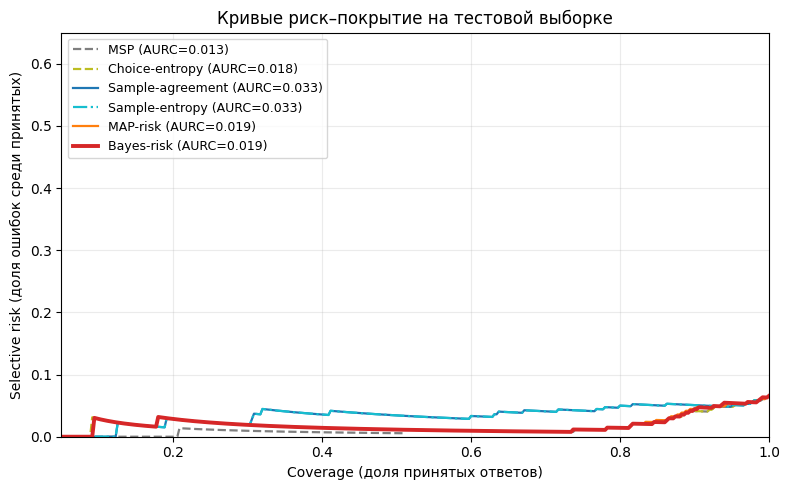

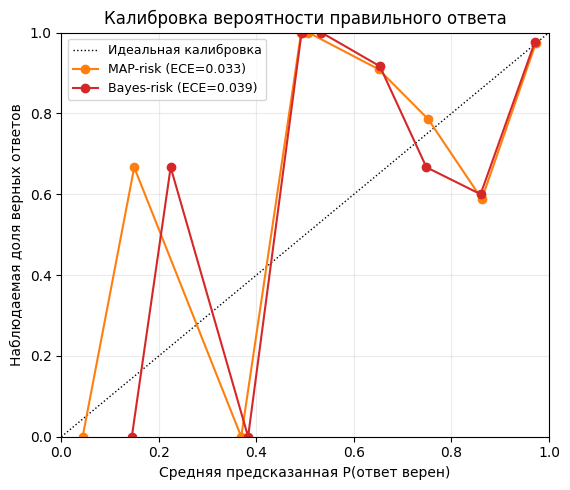

In [13]:
plot_methods = ["MSP", "Choice-entropy", "Sample-agreement", "Sample-entropy", "MAP-risk", "Bayes-risk"]
style = {
    "MSP": ("#7f7f7f", "--"),
    "Choice-entropy": ("#bcbd22", "--"),
    "Sample-agreement": ("#1f77b4", "-"),
    "Sample-entropy": ("#17becf", "-."),
    "MAP-risk": ("#ff7f0e", "-"),
    "Bayes-risk": ("#d62728", "-"),
}

fig_risk, ax = plt.subplots(figsize=(8, 5))
for method in plot_methods:
    cov, risk = risk_coverage_curve(Y_TEST, CONFIDENCE[method])
    color, linestyle = style[method]
    label = f"{method} (AURC={aurc_score(Y_TEST, CONFIDENCE[method]):.3f})"
    ax.plot(
        cov, risk, color=color, linestyle=linestyle,
        linewidth=2.8 if method == "Bayes-risk" else 1.6,
        label=label,
    )
ax.set_xlabel("Coverage (доля принятых ответов)")
ax.set_ylabel("Selective risk (доля ошибок среди принятых)")
ax.set_xlim(0.05, 1.0)
ax.set_ylim(0.0, min(1.0, max(0.65, float(np.max(1 - Y_TEST.mean())) + 0.15)))
ax.grid(alpha=0.25)
ax.legend(loc="upper left", fontsize=9, frameon=True)
ax.set_title("Кривые риск–покрытие на тестовой выборке")
fig_risk.tight_layout()
plt.show()


def reliability_points(y, p, n_bins=N_ECE_BINS):
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    bin_ids = np.clip(np.digitize(p, edges[1:-1]), 0, n_bins - 1)
    xs, ys, ns = [], [], []
    for b in range(n_bins):
        mask = bin_ids == b
        if mask.any():
            xs.append(float(p[mask].mean()))
            ys.append(float(y[mask].mean()))
            ns.append(int(mask.sum()))
    return np.array(xs), np.array(ys), np.array(ns)


fig_cal, ax = plt.subplots(figsize=(5.8, 5))
ax.plot([0, 1], [0, 1], color="black", linestyle=":", linewidth=1, label="Идеальная калибровка")
for method, color in (("MAP-risk", "#ff7f0e"), ("Bayes-risk", "#d62728")):
    p = CONFIDENCE[method]
    xs, ys, ns = reliability_points(Y_TEST, p)
    ax.plot(xs, ys, marker="o", color=color, label=f"{method} (ECE={ece_score(Y_TEST, p):.3f})")
ax.set_xlabel("Средняя предсказанная P(ответ верен)")
ax.set_ylabel("Наблюдаемая доля верных ответов")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.grid(alpha=0.25)
ax.legend(loc="upper left", fontsize=9)
ax.set_title("Калибровка вероятности правильного ответа")
fig_cal.tight_layout()
plt.show()

## 8. Автоматический отчёт

In [14]:
summary_idx = summary.set_index("Method")
bootstrap_idx = bootstrap_table.set_index("Baseline")
base_accuracy = float(Y_TEST.mean())
n_test = len(Y_TEST)

def interpretation(delta, lo, hi, positive_means_better=True):
    if lo > 0:
        return "интервал целиком выше нуля: в этой выборке различие устойчиво в сторону Bayes-risk"
    if hi < 0:
        return "интервал целиком ниже нуля: в этой выборке Bayes-risk хуже базовой оценки"
    return "интервал включает ноль: ясного различия в этой выборке нет"

agreement_delta = float(bootstrap_idx.loc["Sample-agreement", "Δ AURC (baseline − Bayes)"])
agreement_lo = float(bootstrap_idx.loc["Sample-agreement", "AURC CI 2.5%"])
agreement_hi = float(bootstrap_idx.loc["Sample-agreement", "AURC CI 97.5%"])
map_delta = float(bootstrap_idx.loc["MAP-risk", "Δ AURC (baseline − Bayes)"])
map_lo = float(bootstrap_idx.loc["MAP-risk", "AURC CI 2.5%"])
map_hi = float(bootstrap_idx.loc["MAP-risk", "AURC CI 97.5%"])

no_label_methods = ["MSP", "Choice-entropy", "Sample-agreement", "Sample-entropy"]
best_non_bayes = summary[summary["Method"].isin(no_label_methods)].sort_values("AURC ↓").iloc[0]
bayes_aurc = float(summary_idx.loc["Bayes-risk", "AURC ↓"])
map_aurc = float(summary_idx.loc["MAP-risk", "AURC ↓"])
agreement_aurc = float(summary_idx.loc["Sample-agreement", "AURC ↓"])
bayes_risk80 = float(summary_idx.loc["Bayes-risk", "Risk@80% ↓"])
map_risk80 = float(summary_idx.loc["MAP-risk", "Risk@80% ↓"])
mean_msp = float(test_features["msp"].mean())

low_signal_warning = ""
if base_accuracy < 0.55:
    low_signal_warning = f"""
> **Ограничение сигнала.** Полная точность модели {base_accuracy:.1%} при случайном уровне 25.0 %; средний MSP = {mean_msp:.3f}. На такой близкой к случайной точности различия между оценками неопределённости особенно нестабильны, а вывод о превосходстве калибровки нельзя считать содержательным. Для основного анализа используйте более сильную модель, другой промпт или бенчмарк и больше калибровочных данных.
"""

report = f"""
### Фактические результаты

{low_signal_warning}

- Тестовая выборка: **{n_test}** вопросов; полная точность модели: **{base_accuracy:.3f}** (случайный выбор: 0.250); средний MSP: **{mean_msp:.3f}**.
- AURC `Bayes-risk`: **{bayes_aurc:.4f}**; `Sample-agreement`: **{agreement_aurc:.4f}**; `MAP-risk`: **{map_aurc:.4f}**.
- Лучшая оценка без калибровки по меткам в этом запуске: **{best_non_bayes['Method']}** (AURC {best_non_bayes['AURC ↓']:.4f}). Это описание тестовой выборки, а не подтверждающий вывод.
- Риск при покрытии 80 %: `Bayes-risk` **{bayes_risk80:.3f}**, `MAP-risk` **{map_risk80:.3f}**.

**Bayes-risk vs Sample-agreement.** Δ AURC = **{agreement_delta:+.4f}**, 95 % bootstrap CI [{agreement_lo:+.4f}; {agreement_hi:+.4f}]. {interpretation(agreement_delta, agreement_lo, agreement_hi)}.

**Bayes-risk vs MAP-risk (проверка вклада байесовского усреднения).** Δ AURC = **{map_delta:+.4f}**, 95 % bootstrap CI [{map_lo:+.4f}; {map_hi:+.4f}]. {interpretation(map_delta, map_lo, map_hi)}.

### Как читать вывод

- Если Bayes-risk выигрывает у `Sample-agreement`, но не у `MAP-risk`, основной выигрыш связан с калибровкой по меткам, а не с байесовским усреднением параметров.
- Если Bayes-risk не выигрывает, это отрицательный результат для данной модели, датасета и набора признаков; он не опровергает байесовские методы вообще.
- `Bayes-answer` должен совпадать по AURC с `Sample-agreement` (при равном числе выборок и симметричном приоре). Если это не так, проверьте реализацию и обработку ties.
- Для решения о публикации нужны несколько seed/моделей/датасетов и заранее выбранная первичная метрика. AURC и Risk@80 % здесь вторичны по отношению к общей исследовательской цели и не должны выбираться постфактум.
"""
display(Markdown(report))


### Фактические результаты



- Тестовая выборка: **350** вопросов; полная точность модели: **0.934** (случайный выбор: 0.250); средний MSP: **0.992**.
- AURC `Bayes-risk`: **0.0186**; `Sample-agreement`: **0.0330**; `MAP-risk`: **0.0187**.
- Лучшая оценка без калибровки по меткам в этом запуске: **MSP** (AURC 0.0131). Это описание тестовой выборки, а не подтверждающий вывод.
- Риск при покрытии 80 %: `Bayes-risk` **0.014**, `MAP-risk` **0.014**.

**Bayes-risk vs Sample-agreement.** Δ AURC = **+0.0333**, 95 % bootstrap CI [+0.0060; +0.0667]. интервал целиком выше нуля: в этой выборке различие устойчиво в сторону Bayes-risk.

**Bayes-risk vs MAP-risk (проверка вклада байесовского усреднения).** Δ AURC = **+0.0001**, 95 % bootstrap CI [-0.0001; +0.0006]. интервал включает ноль: ясного различия в этой выборке нет.

### Как читать вывод

- Если Bayes-risk выигрывает у `Sample-agreement`, но не у `MAP-risk`, основной выигрыш связан с калибровкой по меткам, а не с байесовским усреднением параметров.
- Если Bayes-risk не выигрывает, это отрицательный результат для данной модели, датасета и набора признаков; он не опровергает байесовские методы вообще.
- `Bayes-answer` должен совпадать по AURC с `Sample-agreement` (при равном числе выборок и симметричном приоре). Если это не так, проверьте реализацию и обработку ties.
- Для решения о публикации нужны несколько seed/моделей/датасетов и заранее выбранная первичная метрика. AURC и Risk@80 % здесь вторичны по отношению к общей исследовательской цели и не должны выбираться постфактум.


## 9. Ограничения и следующие шаги

- **Одна модель и один датасет.** Поведение неопределённости зависит от модели, промпта и домена. SciQ может присутствовать в предобучении Qwen; это завышает точность и может искажать структуру ошибок. Рассмотрите свежий закрытый бенчмарк или вопросы после даты обучения модели.
- **Контролируемый формат.** Один токен A–D устраняет парсинг ответа, но не измеряет семантическую неопределённость свободного текста. Расширение: несколько формулировок промпта, кластеризация свободных ответов, semantic entropy.
- **Байесовская модель — калибратор.** Используются метки, лапласово приближение и фиксированный приор. Проверьте чувствительность к `PRIOR_SCALE`, признакам и альтернативным калибраторам. Для байесовской неопределённости весов LLM нужен другой дизайн (например, MC dropout, ансамбль или приближённый posterior).
- **4-битная квантизация.** NF4 уменьшает память, но добавляет приближение в логиты; калибровка и вероятности могут немного отличаться от BF16/FP16. Для финального сравнения проверьте модель в 16 битах на GPU с достаточной памятью.
- **Исправление в текущей версии.** В раннем прогоне 1.5B индекс последнего токена вычислялся как `sum(attention_mask)-1` при `padding_side="left"`. Для коротких промптов в батче это давало логиты не того токена; старые метрики (включая 45.7% accuracy) не используются как baseline. Сейчас позиция выбирается по маске корректно.
- **Обменность.** Калибровка на `validation` предполагает, что тест похож на неё. При distribution shift порог и калибровка могут деградировать.
- **Малый тест и множественные сравнения.** 350 вопросов дают широкие интервалы; выводы по нескольким baseline'ам исследовательские. Для подтверждающего анализа зафиксируйте одну первичную гипотезу и метрику до просмотра теста, увеличьте выборку и используйте поправку на множественность.
- **Дискретные оценки и ties.** У `Sample-agreement` всего `K+1` возможных значений, поэтому многие вопросы имеют одинаковый score. Кривая риск–покрытие упорядочивает ties детерминированно (по порядку строк); bootstrap частично отражает эту неопределённость, но для публикации полезна tie-aware AURC или большее `K`.
- **Порог отбора.** В таблице риск при фиксированном покрытии оценивается по ранжированию на тесте. Для реального развёртывания порог нужно выбирать только на калибровке или применять conformal/Bayesian risk control с гарантией на ошибку.
- **Оценка значимости.** Парный bootstrap не учитывает неопределённость выбора модели, промпта и случайности обучения. Для публикации добавьте несколько seed, моделей и датасетов.

Практическое расширение: сравнить этот пайплайн с conformal prediction, temperature scaling, ансамблем моделей и semantic entropy на открытых ответах; отдельно измерить coverage при заданном error budget.

## 10. Сохранение артефактов

В Colab файлы появятся в `runs/<run_name>/`. Архив можно скачать через панель файлов или добавить `files.download(str(archive_path))` в отдельную ячейку.

In [15]:
RUN_DIR.mkdir(parents=True, exist_ok=True)

predictions_cols = [
    "qid", "question", "options", "correct_letter", "pred_letter", "correct",
    "p_A", "p_B", "p_C", "p_D",
    "msp", "choice_margin", "choice_entropy_norm",
    "sample_agreement", "sample_entropy_norm",
    "bayes_answer_conf", "p_correct_map", "p_correct_bayes",
    "epistemic_bayes", "sample_counts",
]
test_features[predictions_cols].to_csv(RUN_DIR / "predictions_test.csv", index=False)
cal_features[["qid", "correct", "p_correct_map", "p_correct_bayes"]].to_csv(
    RUN_DIR / "predictions_calibration.csv", index=False
)
summary.to_csv(RUN_DIR / "metrics_summary.csv", index=False)
bootstrap_table.to_csv(RUN_DIR / "bootstrap_deltas.csv", index=False)
coef_table.to_csv(RUN_DIR / "bayes_coefficients.csv", index=False)
(RUN_DIR / "report.md").write_text(report, encoding="utf-8")

fig_risk.savefig(RUN_DIR / "risk_coverage.png", dpi=180, bbox_inches="tight")
fig_cal.savefig(RUN_DIR / "calibration.png", dpi=180, bbox_inches="tight")

config_snapshot = {
    "model_id": MODEL_ID,
    "dataset_id": DATASET_ID,
    "n_calibration": N_CALIBRATION,
    "n_test": N_TEST,
    "n_samples": N_SAMPLES,
    "batch_size": BATCH_SIZE,
    "seed": SEED,
    "load_in_4bit": LOAD_IN_4BIT,
    "quantization": "nf4" if LOAD_IN_4BIT else None,
    "compute_dtype": str(model_dtype).replace("torch.", ""),
    "dirichlet_alpha": DIRICHLET_ALPHA,
    "prior_scale": PRIOR_SCALE,
    "n_posterior_draws": N_POSTERIOR_DRAWS,
    "n_bootstrap": N_BOOTSTRAP,
    "target_coverages": list(TARGET_COVERAGES),
    "device": DEVICE,
    "test_accuracy": base_accuracy,
}
(RUN_DIR / "config.json").write_text(
    json.dumps(config_snapshot, ensure_ascii=False, indent=2), encoding="utf-8"
)

archive_path = RUN_DIR.parent / f"{RUN_DIR.name}.zip"
with zipfile.ZipFile(archive_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for file_path in sorted(RUN_DIR.rglob("*")):
        if file_path.is_file():
            archive.write(file_path, arcname=file_path.relative_to(RUN_DIR.parent))

print(f"Сохранено: {RUN_DIR.resolve()}")
print(f"Архив: {archive_path.resolve()}")
display(summary.round(4))

Сохранено: /content/runs/sciq_qwen25_7b_4bit_bayes_selective_mvp
Архив: /content/runs/sciq_qwen25_7b_4bit_bayes_selective_mvp.zip


,Method,AURC ↓,AUROC ↑,Mean confidence,Risk@50% ↓,Risk@70% ↓,Risk@80% ↓,Risk@90% ↓,Brier ↓,ECE ↓
0,MSP,0.0131,0.8717,0.9923,0.0057,0.0082,0.0143,0.0413,NaN,NaN
1,Choice-entropy,0.0185,0.8548,0.9855,0.0114,0.0082,0.0143,0.0413,NaN,NaN
2,Bayes-risk,0.0186,0.8515,0.9298,0.0114,0.0082,0.0143,0.0444,0.0533,0.0390
3,MAP-risk,0.0187,0.8498,0.9327,0.0114,0.0082,0.0143,0.0444,0.0543,0.0327
4,Sample-entropy,0.0330,0.6188,0.9871,0.0343,0.0408,0.0500,0.0508,NaN,NaN
5,Sample-agreement,0.0330,0.6188,0.9921,0.0343,0.0408,0.0500,0.0508,NaN,NaN
6,Bayes-answer,0.0330,0.6188,0.8437,0.0343,0.0408,0.0500,0.0508,NaN,NaN
